# Trabalho 09 — Mapas Auto-Organizáveis de Kohonen (SOM)
**Exercício 4.1 — Fausett, *Fundamentals of Neural Networks* (1994)**

| | |
|---|---|
| Disciplina | EL056 – Redes Neurais Artificiais (PPGEELT/UFU) |
| Professor | Prof. Dr. Keiji Yamanaka |
| Aluno | Lucas Albino Martins — matrícula 12622EEL006 |

Neste notebook implementamos, em Python puro + NumPy, uma rede de Kohonen com **2 entradas** e **50 unidades de cluster em topologia linear**, treinada com 100 pontos uniformes no disco $x_1^2+x_2^2<0{,}25$. Acompanhamos a cada 10 épocas como a cadeia de vetores de peso $C_1$–$C_2$–…–$C_{50}$ sai de um emaranhado aleatório e passa a serpentear pelo disco.

## 1. Fundamentos

O SOM (*Self-Organizing Map*) é uma rede de **aprendizado competitivo não supervisionado**. A cada padrão $\mathbf{x}$ apresentado:

1. **Competição** — calcula-se, para cada unidade $j$, $D(j)=\sum_i (w_{ij}-x_i)^2$ e escolhe-se o vencedor $J=\arg\min_j D(j)$.
2. **Cooperação** — além de $J$, aprendem as unidades **topologicamente vizinhas** de $J$ (aqui, $J-1$ e $J+1$, pois $R=1$). Nas bordas o vizinho inexistente é ignorado.
3. **Adaptação** — $w_{ij}(\text{novo}) = w_{ij}(\text{velho}) + \alpha\,[x_i - w_{ij}(\text{velho})]$.

Como unidades vizinhas na linha são puxadas para a mesma região do plano, o mapa tende a **preservar a topologia**: unidades próximas na cadeia passam a representar regiões próximas do espaço de entrada.

In [1]:
import csv, os
from typing import Callable, Dict, List
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

## 2. Parâmetros do enunciado

In [2]:
N_ENTRADAS = 2          # dimensao do vetor de entrada (x1, x2)
N_CLUSTERS = 50         # unidades de cluster na topologia linear
RAIO_VIZINHANCA = 1     # R = 1 (fixo): vencedor J, J-1 e J+1
ALFA_INICIAL = 0.5
ALFA_FINAL = 0.01
N_EPOCAS = 100
N_PONTOS = 100
RAIO_DISCO = 0.5        # x1^2 + x2^2 < 0,25  <=>  raio 0,5
SEED_PADRAO = 42       # seed da rede (pesos iniciais + ordem dos padroes)
SEED_DADOS = 2026      # seed independente para os dados de treino
EPOCAS_PLOT = list(range(0, N_EPOCAS + 1, 10))   # 0, 10, 20, ..., 100

## 3. Decaimento da taxa de aprendizado

O enunciado pede $\alpha$ reduzido gradualmente de 0,5 até 0,01 em 100 épocas. Adotamos como padrão o **decaimento linear por época**,
$$\alpha(t)=\alpha_0+(\alpha_f-\alpha_0)\,\frac{t}{T-1},\qquad t=0,\dots,T-1,$$
que é a interpretação mais literal de "reduzir gradualmente" e mantém $\alpha$ alto por mais tempo (fase de ordenação longa). A primeira época usa exatamente 0,5 e a última exatamente 0,01. A função é um parâmetro de `treinar`, e também implementamos o **decaimento exponencial** (geométrico) $\alpha(t)=\alpha_0(\alpha_f/\alpha_0)^{t/(T-1)}$ para comparação.

In [3]:
# Cada funcao recebe o indice da epoca (0 = primeira epoca de treino) e o
# numero total de epocas, e devolve o alfa usado durante aquela epoca.
# A primeira epoca usa exatamente ALFA_INICIAL e a ultima exatamente
# ALFA_FINAL, de modo que "0,5 reduzido gradualmente ate 0,01 em 100 epocas"
# seja cumprido literalmente.

def decaimento_linear(epoca: int, n_epocas: int,
                      a0: float = ALFA_INICIAL, af: float = ALFA_FINAL) -> float:
    """alfa(t) = a0 + (af - a0) * t / (T - 1),  t = 0, ..., T-1."""
    if n_epocas <= 1:
        return a0
    return a0 + (af - a0) * epoca / (n_epocas - 1)


def decaimento_exponencial(epoca: int, n_epocas: int,
                           a0: float = ALFA_INICIAL, af: float = ALFA_FINAL) -> float:
    """alfa(t) = a0 * (af / a0) ** (t / (T - 1))  (geometrico entre a0 e af)."""
    if n_epocas <= 1:
        return a0
    return a0 * (af / a0) ** (epoca / (n_epocas - 1))


DECAIMENTOS: Dict[str, Callable[[int, int], float]] = {
    "linear": decaimento_linear,
    "exponencial": decaimento_exponencial,
}

## 4. Dados de treino (amostragem por rejeição)

Sorteamos $x_1,x_2\sim U(-0{,}5;\,0{,}5)$ e aceitamos o ponto apenas se $x_1^2+x_2^2<0{,}25$. A taxa de aceitação esperada é a razão entre a área do disco e a do quadrado, $\pi/4\approx0{,}785$.

In [4]:
def gerar_dados_disco(n_pontos: int, rng: np.random.Generator,
                      raio: float = RAIO_DISCO) -> np.ndarray:
    """Sorteia x1, x2 ~ U(-raio, raio) e aceita o ponto somente se
    x1^2 + x2^2 < raio^2, repetindo ate obter n_pontos pontos aceitos."""
    pontos: List[np.ndarray] = []
    n_sorteios = 0
    while len(pontos) < n_pontos:
        candidato = rng.uniform(-raio, raio, size=2)
        n_sorteios += 1
        if candidato[0] ** 2 + candidato[1] ** 2 < raio ** 2:
            pontos.append(candidato)
    taxa = n_pontos / n_sorteios
    print(f"[dados] {n_pontos} pontos aceitos em {n_sorteios} sorteios "
          f"(taxa de aceitacao = {taxa:.3f}; teorico pi/4 = {np.pi/4:.3f})")
    return np.array(pontos)


def salvar_csv(caminho: str, dados: np.ndarray) -> None:
    with open(caminho, "w", newline="", encoding="utf-8") as f:
        escritor = csv.writer(f)
        escritor.writerow(["indice", "x1", "x2"])
        for i, (x1, x2) in enumerate(dados, start=1):
            escritor.writerow([i, f"{x1:.10f}", f"{x2:.10f}"])


def carregar_csv(caminho: str) -> np.ndarray:
    return np.loadtxt(caminho, delimiter=",", skiprows=1, usecols=(1, 2))

## 5. A rede de Kohonen linear

A matriz `pesos` tem forma $50\times 2$: a linha $j$ é o vetor de pesos da unidade $C_{j+1}$. Além do treino, a classe calcula três métricas usadas na análise:
- **erro de quantização (EQ)**: distância média de cada ponto ao seu vencedor;
- **cruzamentos**: pares de segmentos não adjacentes da cadeia que se cruzam (0 = curva sem "nós");
- **unidades mortas**: unidades que não vencem para nenhum ponto de treino.

In [5]:
class SOMLinear:
    """Mapa auto-organizavel de Kohonen com unidades de cluster em linha.

    Os pesos ficam em uma matriz `pesos` de forma (n_clusters, n_entradas):
    a linha j e o vetor de pesos w_.j da unidade de cluster C_{j+1}
    (indexacao 0 no codigo, 1 no texto).
    """

    def __init__(self, n_entradas: int = N_ENTRADAS, n_clusters: int = N_CLUSTERS,
                 raio: int = RAIO_VIZINHANCA, rng: np.random.Generator | None = None):
        self.n_entradas = n_entradas
        self.n_clusters = n_clusters
        self.raio = raio
        self.rng = rng if rng is not None else np.random.default_rng(SEED_PADRAO)
        # Pesos iniciais: cada componente ~ U(-1, 1)
        self.pesos = self.rng.uniform(-1.0, 1.0, size=(n_clusters, n_entradas))

    # ---- competicao ---------------------------------------------------------
    def distancias_quadradas(self, x: np.ndarray) -> np.ndarray:
        """D(j) = sum_i (w_ij - x_i)^2 para todas as unidades j."""
        return np.sum((self.pesos - x) ** 2, axis=1)

    def vencedor(self, x: np.ndarray) -> int:
        """Indice J da unidade com menor distancia euclidiana ao quadrado."""
        return int(np.argmin(self.distancias_quadradas(x)))

    # ---- cooperacao ---------------------------------------------------------
    def vizinhanca(self, J: int) -> range:
        """Unidades J-R, ..., J+R, descartando as que caem fora de [0, n-1]
        (nas bordas o vizinho inexistente e simplesmente ignorado)."""
        inicio = max(0, J - self.raio)
        fim = min(self.n_clusters - 1, J + self.raio)
        return range(inicio, fim + 1)

    # ---- adaptacao ----------------------------------------------------------
    def atualizar(self, x: np.ndarray, alfa: float) -> int:
        """w_ij(new) = w_ij(old) + alfa * (x_i - w_ij(old)) para j na vizinhanca."""
        J = self.vencedor(x)
        for j in self.vizinhanca(J):
            self.pesos[j] += alfa * (x - self.pesos[j])
        return J

    def treinar_epoca(self, dados: np.ndarray, alfa: float) -> None:
        """Uma epoca: todos os padroes, em ordem aleatoria (nova a cada epoca)."""
        for indice in self.rng.permutation(len(dados)):
            self.atualizar(dados[indice], alfa)

    # ---- metricas -----------------------------------------------------------
    def erro_quantizacao(self, dados: np.ndarray) -> float:
        """Distancia euclidiana media de cada ponto ao vetor de pesos vencedor."""
        d2 = np.sum((dados[:, None, :] - self.pesos[None, :, :]) ** 2, axis=2)
        return float(np.mean(np.sqrt(d2.min(axis=1))))

    def comprimento_cadeia(self) -> float:
        """Soma dos comprimentos dos segmentos C1-C2-...-C50."""
        return float(np.sum(np.linalg.norm(np.diff(self.pesos, axis=0), axis=1)))

    def n_cruzamentos(self) -> int:
        """Numero de pares de segmentos nao adjacentes da cadeia que se cruzam.
        Zero cruzamentos = curva sem "nos" (preservacao topologica no plano)."""
        P = self.pesos
        n_seg = len(P) - 1

        def orient(a, b, c):
            return np.sign((b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0]))

        total = 0
        for i in range(n_seg):
            for k in range(i + 2, n_seg):
                a, b, c, d = P[i], P[i + 1], P[k], P[k + 1]
                if (orient(a, b, c) * orient(a, b, d) < 0 and
                        orient(c, d, a) * orient(c, d, b) < 0):
                    total += 1
        return total

    def unidades_mortas(self, dados: np.ndarray) -> int:
        """Unidades que nao vencem para nenhum padrao de treino."""
        d2 = np.sum((dados[:, None, :] - self.pesos[None, :, :]) ** 2, axis=2)
        return self.n_clusters - len(np.unique(d2.argmin(axis=1)))

## 6. Laço de treino

Cada época apresenta os 100 padrões em uma **nova ordem aleatória**. Guardamos os pesos nas épocas 0 (antes do treino), 10, 20, …, 100.

In [6]:
def raio_decrescente(epoca: int, n_epocas: int, r0: int = 10, epoca_r1: int = 50) -> int:
    """(Somente analise extra, fora do enunciado) raio que cai linearmente de
    r0 ate 1 nas primeiras `epoca_r1` epocas e fica em 1 dai em diante."""
    return max(1, int(round(r0 - (r0 - 1) * epoca / epoca_r1)))


def treinar(dados: np.ndarray, seed: int = SEED_PADRAO, n_epocas: int = N_EPOCAS,
            decaimento: Callable[[int, int], float] = decaimento_linear,
            epocas_registro: List[int] | None = None, verbose: bool = True,
            raio_fn: Callable[[int, int], int] | None = None) -> dict:
    """Treina um SOMLinear e devolve um dicionario com:
    - 'som'        : a rede treinada
    - 'snapshots'  : {epoca: copia dos pesos ao FINAL daquela epoca}
                     (epoca 0 = pesos iniciais, antes do treino)
    - 'alfas'      : alfa usado em cada epoca 1..n_epocas
    - 'erros'      : erro de quantizacao ao final de cada epoca 0..n_epocas
    Se `raio_fn` for dado, o raio de vizinhanca passa a variar por epoca
    (usado apenas na analise extra; o enunciado exige R = 1 fixo).
    """
    if epocas_registro is None:
        epocas_registro = list(range(0, n_epocas + 1, 10))
    rng = np.random.default_rng(seed)
    som = SOMLinear(rng=rng)

    snapshots = {0: som.pesos.copy()}
    alfas: List[float] = []
    erros = [som.erro_quantizacao(dados)]

    if verbose:
        print(f"{'epoca':>6} | {'alfa':>8} | {'erro quant.':>11} | {'cruzam.':>7}")
        print("-" * 44)
        print(f"{0:>6} | {'-':>8} | {erros[0]:>11.5f} | {som.n_cruzamentos():>7}")

    for epoca in range(1, n_epocas + 1):
        alfa = decaimento(epoca - 1, n_epocas)
        if raio_fn is not None:
            som.raio = raio_fn(epoca - 1, n_epocas)
        som.treinar_epoca(dados, alfa)
        alfas.append(alfa)
        erros.append(som.erro_quantizacao(dados))
        if epoca in epocas_registro:
            snapshots[epoca] = som.pesos.copy()
            if verbose:
                print(f"{epoca:>6} | {alfa:>8.4f} | {erros[-1]:>11.5f} | "
                      f"{som.n_cruzamentos():>7}")

    return {"som": som, "snapshots": snapshots, "alfas": np.array(alfas),
            "erros": np.array(erros)}

## 7. Funções de visualização

In [7]:
COR_DADOS = "#9aa3ad"
COR_REDE = "#1f4e9c"
COR_CIRCULO = "#c0392b"


def desenhar_som(ax, pesos: np.ndarray, dados: np.ndarray, titulo: str = "",
                 limite: float | None = None, rotular_extremos: bool = True) -> None:
    """Pontos de treino + circulo x1^2+x2^2=0,25 + cadeia C1-C2-...-C50.
    Se `limite` for None, o enquadramento se ajusta aos pesos (no minimo
    [-0,6; 0,6], que mostra o disco inteiro; na epoca 0 abre para [-1; 1])."""
    if limite is None:
        limite = max(0.6, float(np.abs(pesos).max()) + 0.05)
    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(RAIO_DISCO * np.cos(theta), RAIO_DISCO * np.sin(theta),
            color=COR_CIRCULO, lw=1.2, ls="--", label=r"$x_1^2+x_2^2=0{,}25$")
    ax.scatter(dados[:, 0], dados[:, 1], s=10, color=COR_DADOS, alpha=0.9,
               label="dados de treino", zorder=2)
    ax.plot(pesos[:, 0], pesos[:, 1], "-", color=COR_REDE, lw=1.1, zorder=3)
    ax.scatter(pesos[:, 0], pesos[:, 1], s=14, color=COR_REDE, zorder=4,
               label="pesos $w_{\\cdot j}$")
    if rotular_extremos:
        for idx, nome in ((0, "C1"), (len(pesos) - 1, f"C{len(pesos)}")):
            ax.annotate(nome, pesos[idx], xytext=(4, 4), textcoords="offset points",
                        fontsize=8, color="black", zorder=5)
    ax.set_xlim(-limite, limite)
    ax.set_ylim(-limite, limite)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$  /  $w_{1j}$")
    ax.set_ylabel("$x_2$  /  $w_{2j}$")
    ax.grid(alpha=0.25)
    if titulo:
        ax.set_title(titulo, fontsize=10)


def salvar_figuras_epocas(snapshots: dict, dados: np.ndarray, pasta: str,
                          alfas: np.ndarray, erros: np.ndarray, dpi: int = 300) -> None:
    for epoca, pesos in sorted(snapshots.items()):
        fig, ax = plt.subplots(figsize=(5.2, 5.2))
        if epoca == 0:
            titulo = "Época 0 (pesos iniciais)"
        else:
            titulo = (f"Época {epoca}  \u2014  \u03b1 = {alfas[epoca-1]:.3f}  \u2014  "
                      f"EQ = {erros[epoca]:.4f}")
        desenhar_som(ax, pesos, dados, titulo)
        ax.legend(loc="upper right", fontsize=7, framealpha=0.9)
        fig.tight_layout()
        fig.savefig(os.path.join(pasta, f"som_epoca_{epoca:03d}.png"), dpi=dpi)
        plt.close(fig)


def salvar_painel(snapshots: dict, dados: np.ndarray, caminho: str,
                  erros: np.ndarray, dpi: int = 300) -> None:
    epocas = sorted(snapshots)
    n_col = 4
    n_lin = int(np.ceil(len(epocas) / n_col))
    fig, eixos = plt.subplots(n_lin, n_col, figsize=(3.3 * n_col, 3.3 * n_lin))
    eixos = np.atleast_1d(eixos).ravel()
    for ax, epoca in zip(eixos, epocas):
        rot = "Época 0 (inicial)" if epoca == 0 else f"Época {epoca} (EQ={erros[epoca]:.3f})"
        desenhar_som(ax, snapshots[epoca], dados, rot, rotular_extremos=False)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(labelsize=7)
    for ax in eixos[len(epocas):]:
        ax.axis("off")
    fig.suptitle("Evolução do SOM linear (50 unidades) a cada 10 épocas", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(caminho, dpi=dpi)
    plt.close(fig)


def salvar_grafico_alfa(alfas_por_nome: Dict[str, np.ndarray], caminho: str,
                        dpi: int = 300) -> None:
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    estilos = {"linear": ("-", COR_REDE), "exponencial": ("--", COR_CIRCULO)}
    for nome, alfas in alfas_por_nome.items():
        ls, cor = estilos.get(nome, ("-", "k"))
        ax.plot(np.arange(1, len(alfas) + 1), alfas, ls, color=cor, lw=1.8,
                label=f"decaimento {nome}")
    ax.set_xlabel("Época")
    ax.set_ylabel(r"Taxa de aprendizado $\alpha$")
    ax.set_title(r"$\alpha$ por época (0,5 $\rightarrow$ 0,01 em 100 épocas)")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(caminho, dpi=dpi)
    plt.close(fig)


def salvar_grafico_erro(erros_por_nome: Dict[str, np.ndarray], caminho: str,
                        dpi: int = 300) -> None:
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    estilos = {"linear": ("-", COR_REDE), "exponencial": ("--", COR_CIRCULO)}
    for nome, erros in erros_por_nome.items():
        ls, cor = estilos.get(nome, ("-", "k"))
        ax.plot(np.arange(len(erros)), erros, ls, color=cor, lw=1.8,
                label=f"decaimento {nome}")
    ax.set_yscale("log")
    ax.set_xlabel("Época")
    ax.set_ylabel("Erro de quantização médio")
    ax.set_title("Erro de quantização ao final de cada época")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    fig.tight_layout()
    fig.savefig(caminho, dpi=dpi)
    plt.close(fig)


def salvar_comparacao(resultados: Dict[str, dict], dados: np.ndarray, caminho: str,
                      titulo: str, dpi: int = 300) -> None:
    n = len(resultados)
    fig, eixos = plt.subplots(1, n, figsize=(3.6 * n, 4.4))
    eixos = np.atleast_1d(eixos)
    for ax, (nome, res) in zip(eixos, resultados.items()):
        som = res["som"]
        rot = (f"{nome}\nEQ={res['erros'][-1]:.4f}  "
               f"cruz.={som.n_cruzamentos()}  mortas={som.unidades_mortas(dados)}")
        desenhar_som(ax, som.pesos, dados, rot, rotular_extremos=True)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(labelsize=7)
    fig.suptitle(titulo, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(caminho, dpi=dpi)
    plt.close(fig)

## 8. Geração e salvamento dos dados

A seed dos dados (2026) é **independente** da seed da rede (42): se ambos usassem o mesmo gerador, os primeiros pesos seriam cópias escaladas dos primeiros pontos sorteados.

In [8]:
SAIDA = "."
PASTA_FIG = os.path.join(SAIDA, "figuras")
os.makedirs(PASTA_FIG, exist_ok=True)

dados = gerar_dados_disco(N_PONTOS, np.random.default_rng(SEED_DADOS))
salvar_csv(os.path.join(SAIDA, "dados_treino.csv"), dados)
dados = carregar_csv(os.path.join(SAIDA, "dados_treino.csv"))
print(dados.shape, "| max x1^2+x2^2 =", (dados**2).sum(axis=1).max().round(4))

[dados] 100 pontos aceitos em 122 sorteios (taxa de aceitacao = 0.820; teorico pi/4 = 0.785)
(100, 2) | max x1^2+x2^2 = 0.2498


## 9. Treino principal (R = 1, decaimento linear, seed 42)

A cada 10 épocas imprimimos a época, o $\alpha$ em uso, o erro de quantização médio e o número de cruzamentos da cadeia.

In [9]:
principal = treinar(dados, seed=SEED_PADRAO, decaimento=decaimento_linear,
                    epocas_registro=EPOCAS_PLOT)
som = principal["som"]
print(f"\nComprimento da cadeia = {som.comprimento_cadeia():.3f} | "
      f"cruzamentos = {som.n_cruzamentos()} | unidades mortas = {som.unidades_mortas(dados)}")

 epoca |     alfa | erro quant. | cruzam.
--------------------------------------------
     0 |        - |     0.13974 |     209
    10 |   0.4555 |     0.04846 |      15
    20 |   0.4060 |     0.04655 |       4
    30 |   0.3565 |     0.04642 |       4
    40 |   0.3070 |     0.04533 |       4
    50 |   0.2575 |     0.04465 |       4


    60 |   0.2080 |     0.04178 |       4
    70 |   0.1585 |     0.04139 |       4
    80 |   0.1090 |     0.04160 |       4
    90 |   0.0595 |     0.04198 |       4
   100 |   0.0100 |     0.04173 |       4



Comprimento da cadeia = 4.307 | cruzamentos = 4 | unidades mortas = 3


## 10. Evolução da rede a cada 10 épocas

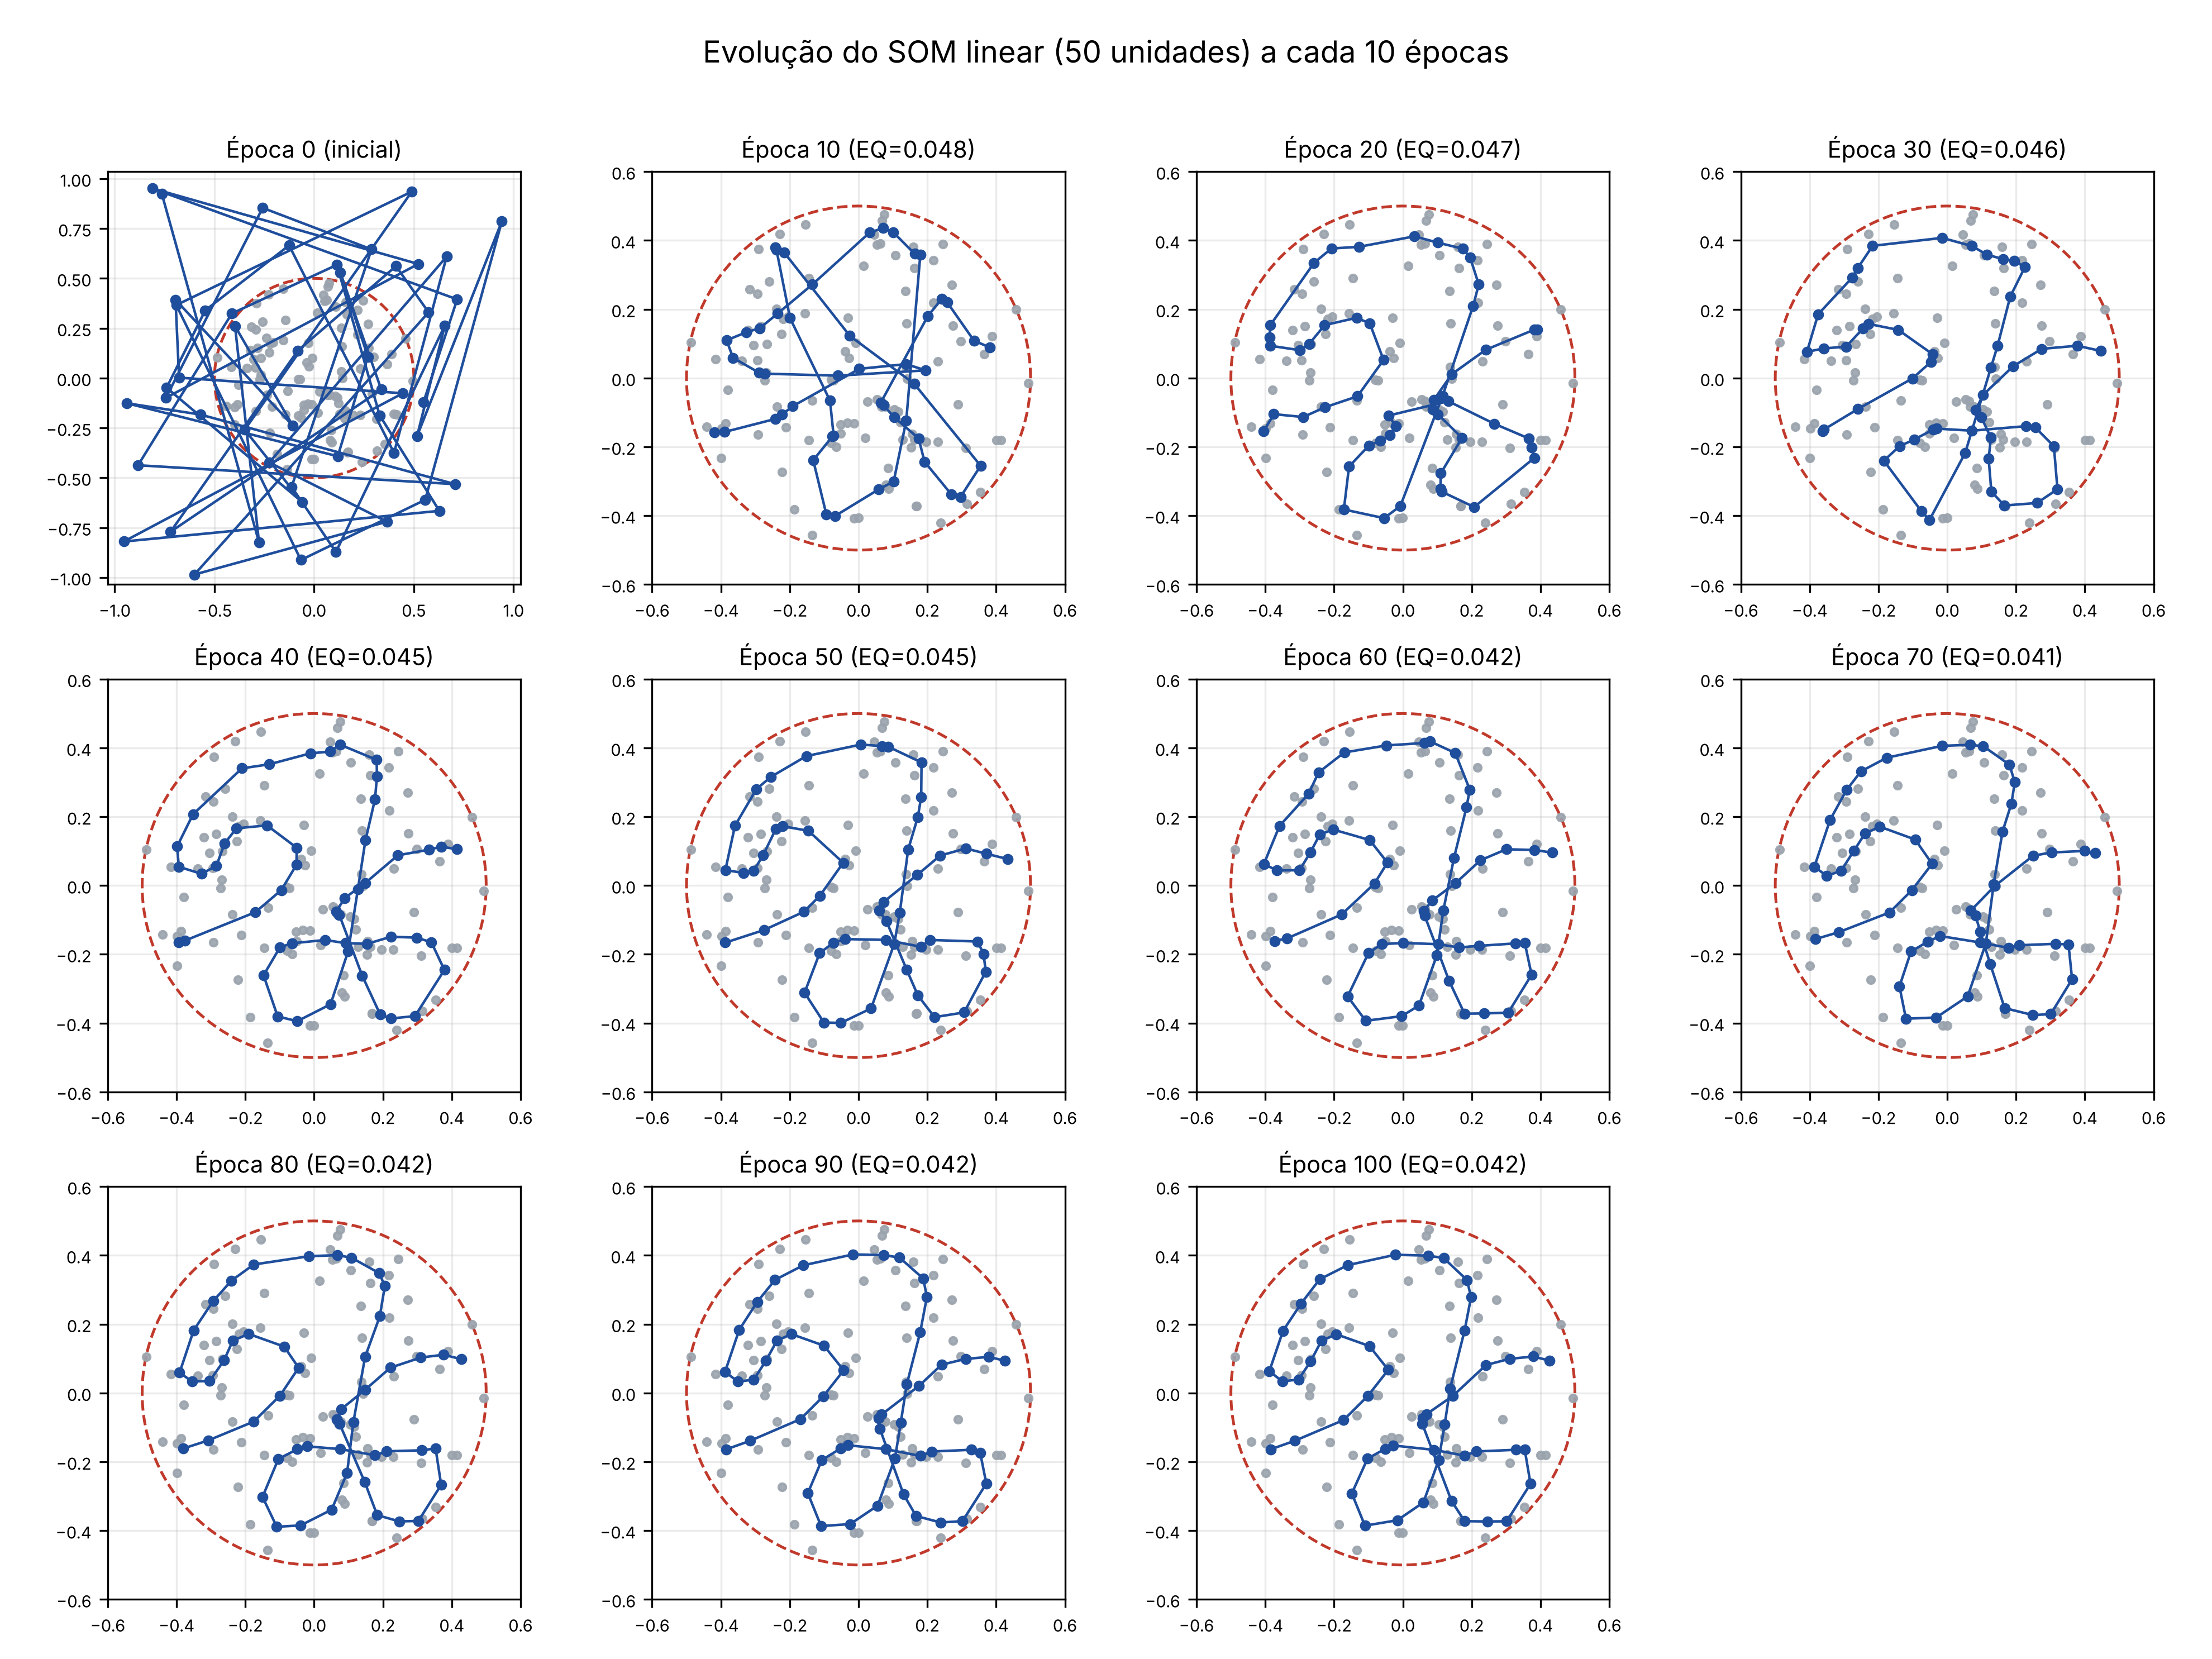

In [10]:
salvar_figuras_epocas(principal["snapshots"], dados, PASTA_FIG,
                      principal["alfas"], principal["erros"])
salvar_painel(principal["snapshots"], dados, os.path.join(PASTA_FIG, "som_painel.png"),
              principal["erros"])
display(Image(os.path.join(PASTA_FIG, "som_painel.png"), width=950))

Época 0 e época 100 em detalhe:

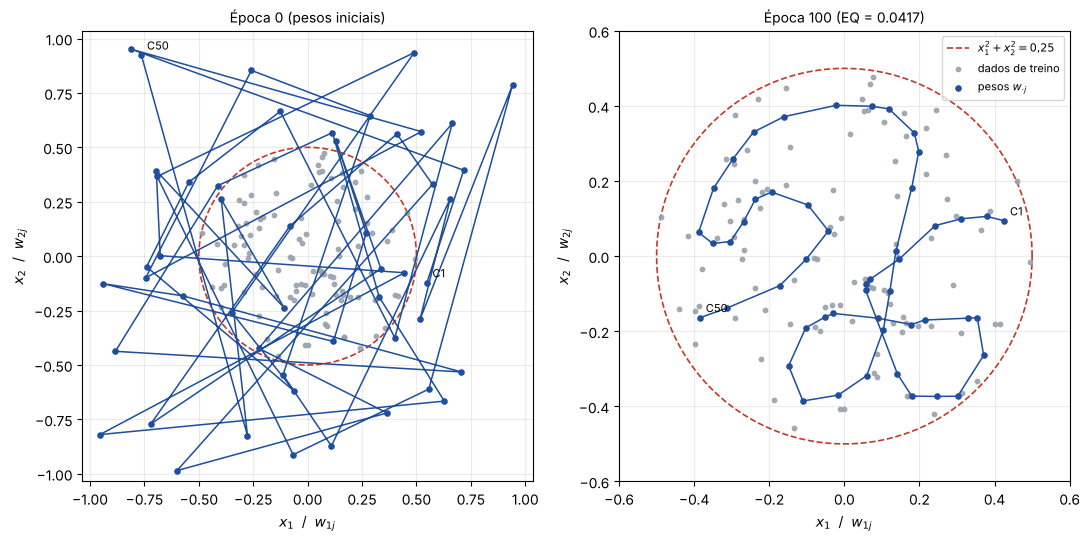

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 5.4))
desenhar_som(eixos[0], principal["snapshots"][0], dados, "Época 0 (pesos iniciais)")
desenhar_som(eixos[1], principal["snapshots"][100], dados,
             f"Época 100 (EQ = {principal['erros'][-1]:.4f})")
eixos[1].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** Na época 0 os 50 pesos estão espalhados no quadrado $[-1,1]^2$ e a cadeia cruza a si mesma centenas de vezes. Já na época 10 todos os pesos foram puxados para dentro do disco e a maior parte dos cruzamentos desapareceu. Daí em diante a forma geral praticamente congela: como $R=1$, cada atualização só arrasta três unidades, o que não basta para desfazer um "nó" grande — e, com $\alpha$ caindo, a rede apenas refina as posições locais. O resultado é uma curva que serpenteia pelo disco, mas que, para esta seed, preserva alguns cruzamentos residuais.

## 11. Análises extras

### 11.1 Decaimento linear × exponencial — e gráficos de $\alpha$ e do erro por época

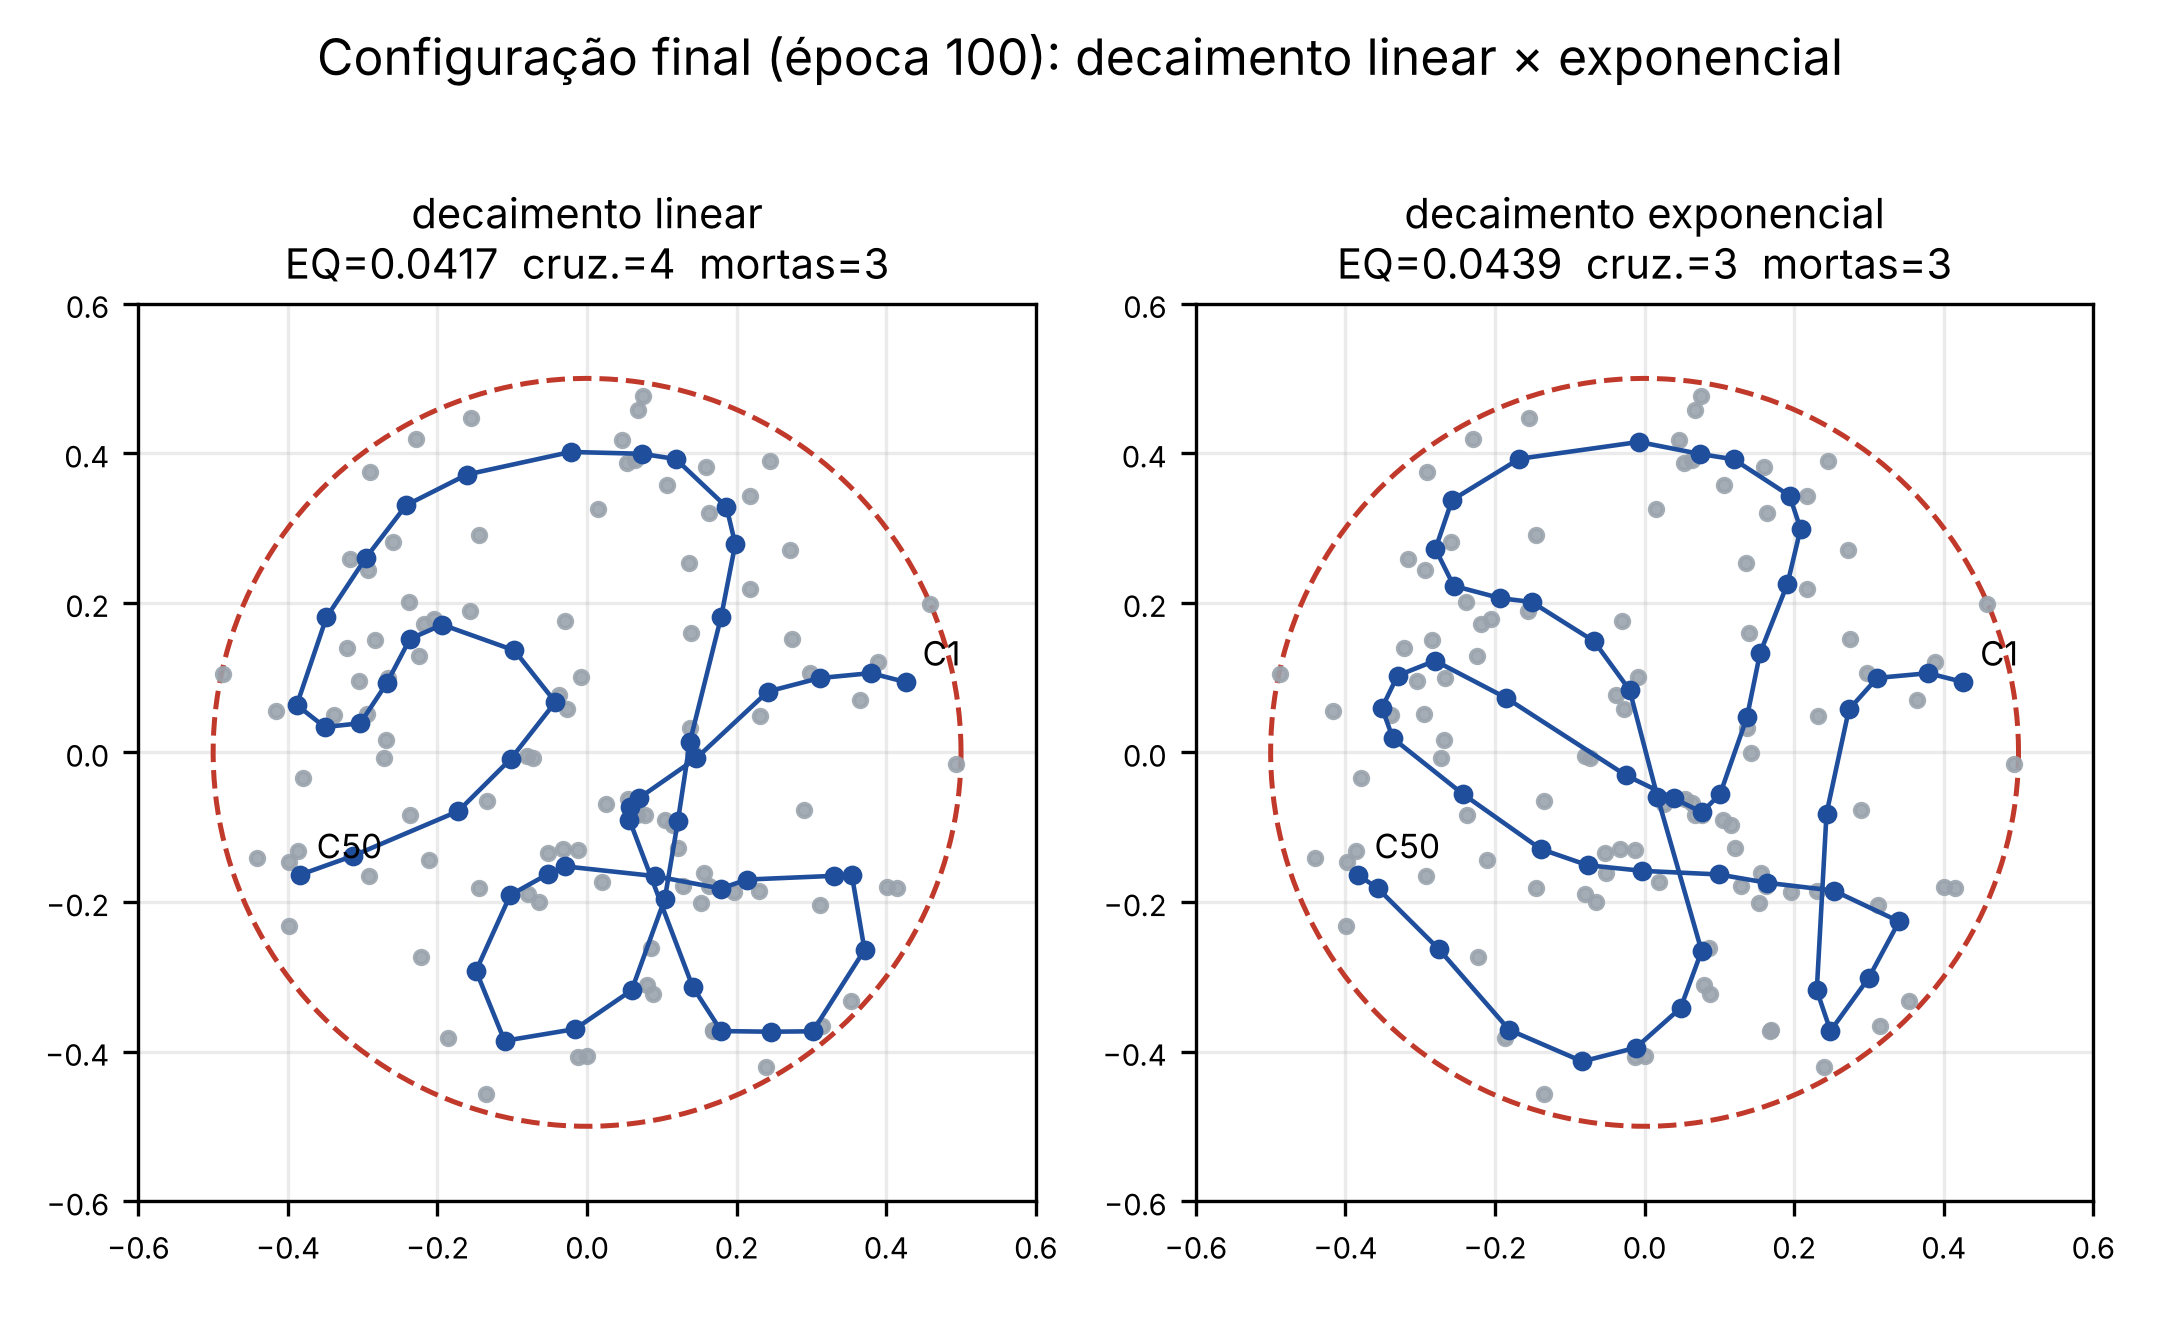

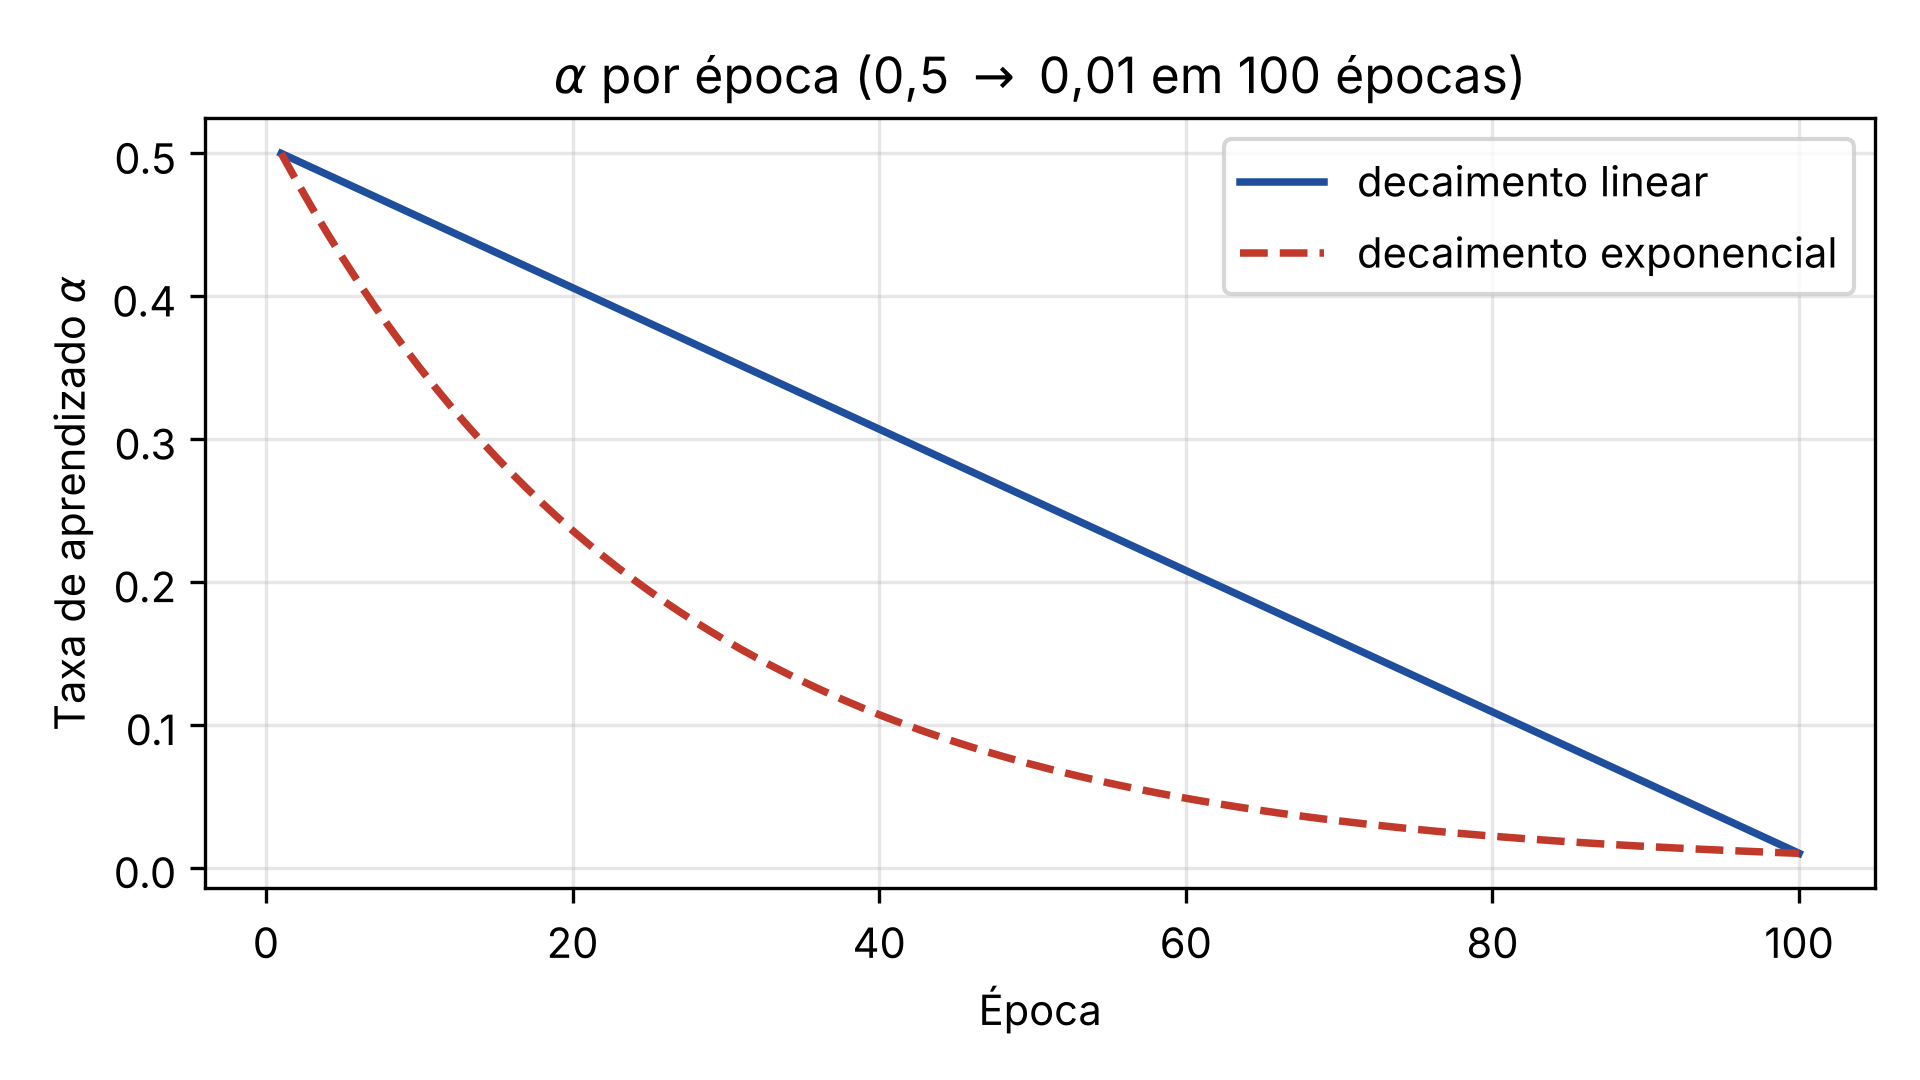

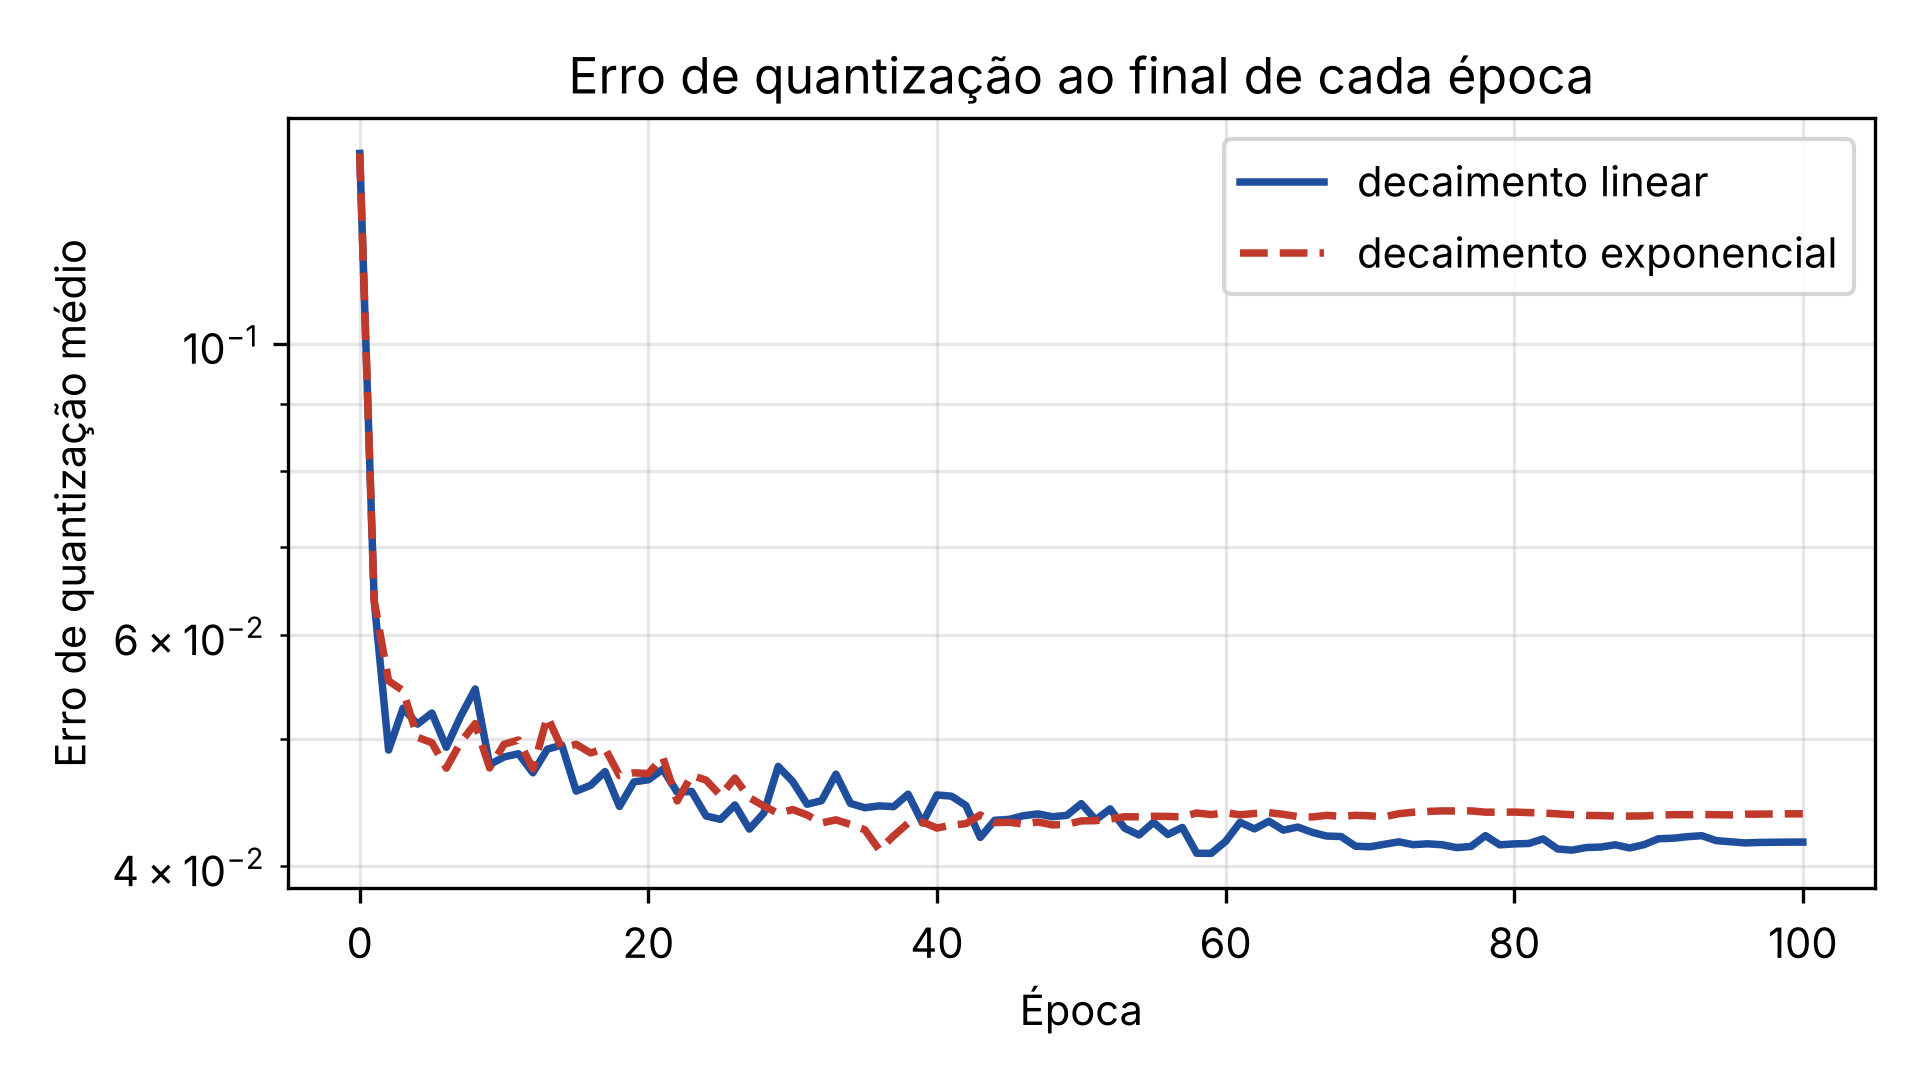

In [12]:
res_exp = treinar(dados, seed=SEED_PADRAO, decaimento=decaimento_exponencial, verbose=False)
salvar_comparacao({"decaimento linear": principal, "decaimento exponencial": res_exp}, dados,
                  os.path.join(PASTA_FIG, "comparacao_decaimento.png"),
                  "Configuração final (época 100): decaimento linear × exponencial")
display(Image(os.path.join(PASTA_FIG, "comparacao_decaimento.png"), width=700))

salvar_grafico_alfa({"linear": principal["alfas"], "exponencial": res_exp["alfas"]},
                    os.path.join(PASTA_FIG, "alpha_por_epoca.png"))
salvar_grafico_erro({"linear": principal["erros"], "exponencial": res_exp["erros"]},
                    os.path.join(PASTA_FIG, "erro_quantizacao.png"))
display(Image(os.path.join(PASTA_FIG, "alpha_por_epoca.png"), width=600))
display(Image(os.path.join(PASTA_FIG, "erro_quantizacao.png"), width=600))

### 11.2 Seeds diferentes (pesos iniciais e ordem de apresentação), mesmos dados

seed      1: EQ = 0.04258 | cruzamentos = 0 | mortas = 4


seed      7: EQ = 0.04307 | cruzamentos = 4 | mortas = 2


seed   2024: EQ = 0.03967 | cruzamentos = 2 | mortas = 1


seed  31415: EQ = 0.04207 | cruzamentos = 2 | mortas = 2


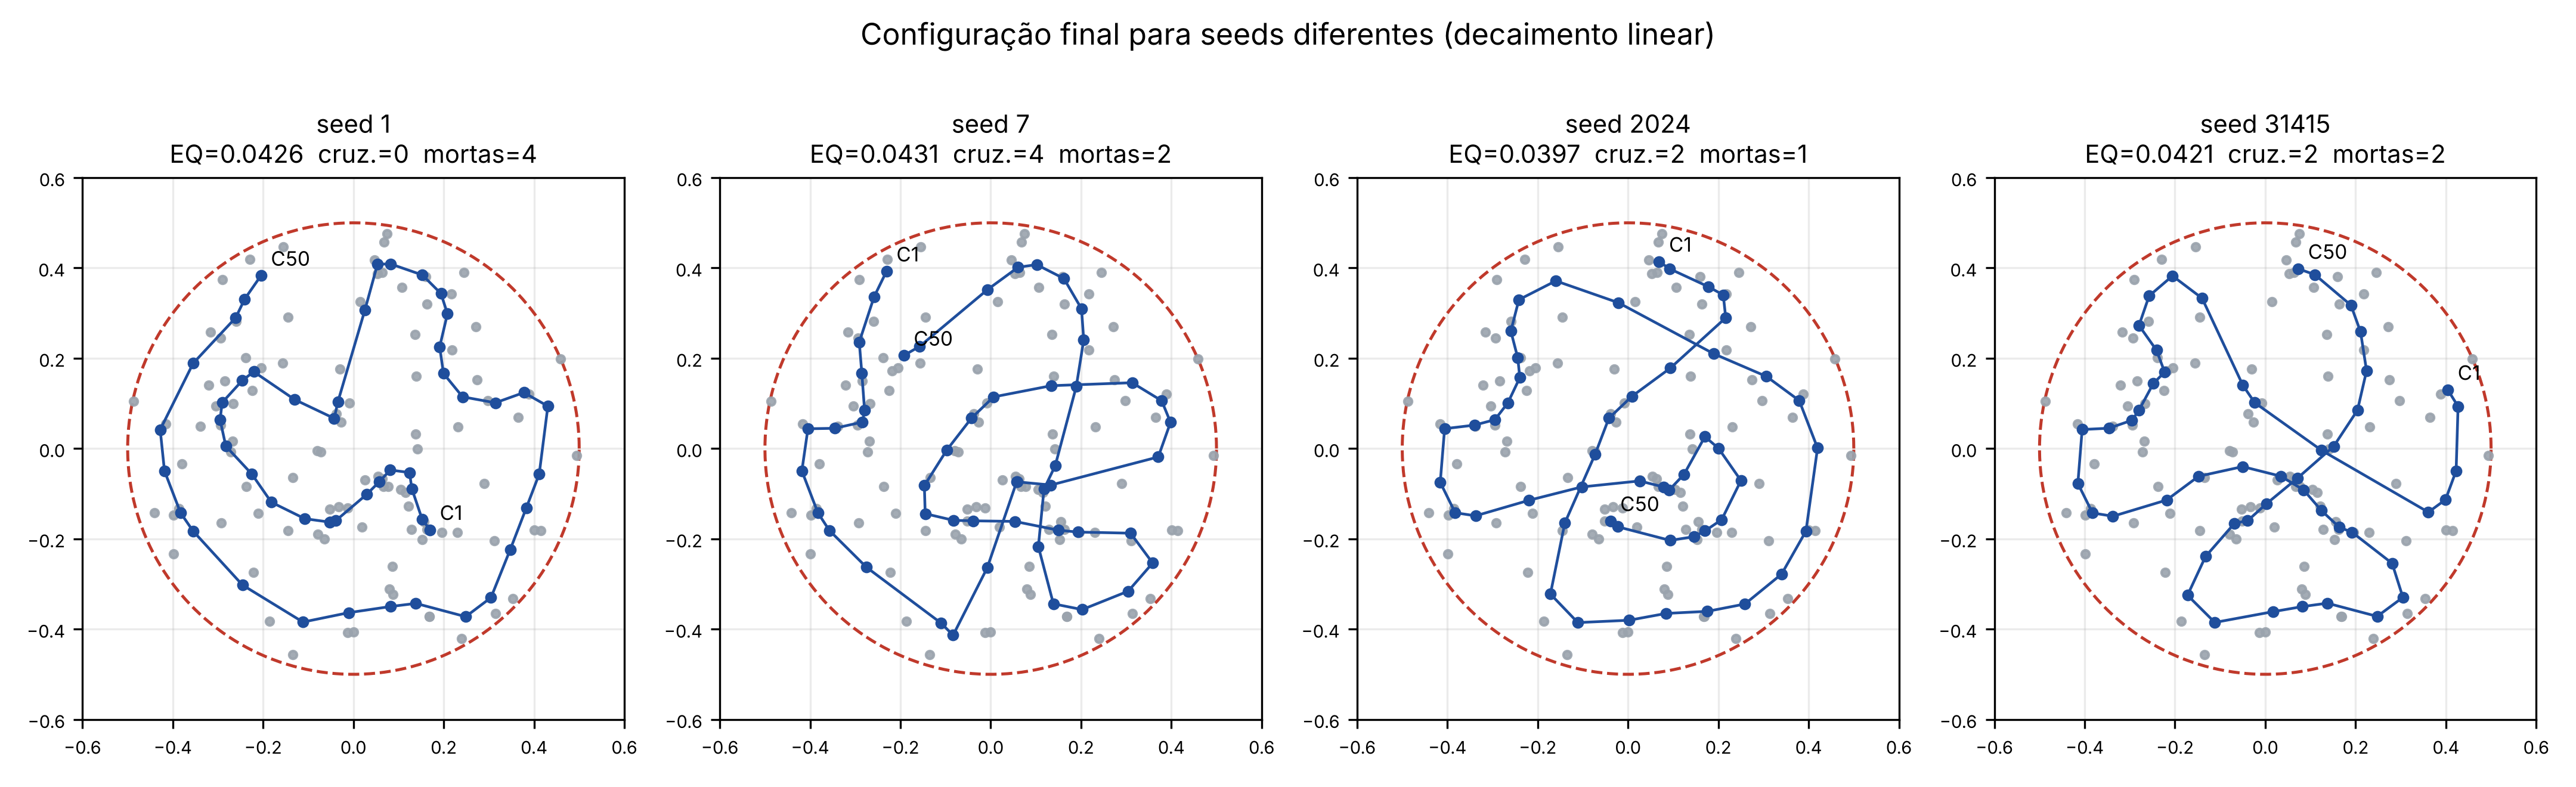

In [13]:
res_seeds = {}
for s in [1, 7, 2024, 31415]:
    r = treinar(dados, seed=s, verbose=False)
    res_seeds[f"seed {s}"] = r
    print(f"seed {s:>6}: EQ = {r['erros'][-1]:.5f} | cruzamentos = {r['som'].n_cruzamentos()}"
          f" | mortas = {r['som'].unidades_mortas(dados)}")
salvar_comparacao(res_seeds, dados, os.path.join(PASTA_FIG, "comparacao_seeds.png"),
                  "Configuração final para seeds diferentes (decaimento linear)")
display(Image(os.path.join(PASTA_FIG, "comparacao_seeds.png"), width=950))

### 11.3 (Fora do enunciado) Raio de vizinhança decrescente

Para confirmar que os nós residuais vêm do raio pequeno, repetimos o treino com a mesma seed, mas com $R$ caindo de 10 até 1 nas primeiras 50 épocas (estratégia clássica de Kohonen).

 epoca |     alfa | erro quant. | cruzam.
--------------------------------------------
     0 |        - |     0.13974 |     209
    10 |   0.4555 |     0.10821 |       0
    20 |   0.4060 |     0.11865 |       0
    30 |   0.3565 |     0.09039 |       0


    40 |   0.3070 |     0.07370 |       0
    50 |   0.2575 |     0.04335 |       0
    60 |   0.2080 |     0.04225 |       0
    70 |   0.1585 |     0.04014 |       0
    80 |   0.1090 |     0.04079 |       0
    90 |   0.0595 |     0.04025 |       0


   100 |   0.0100 |     0.04015 |       0


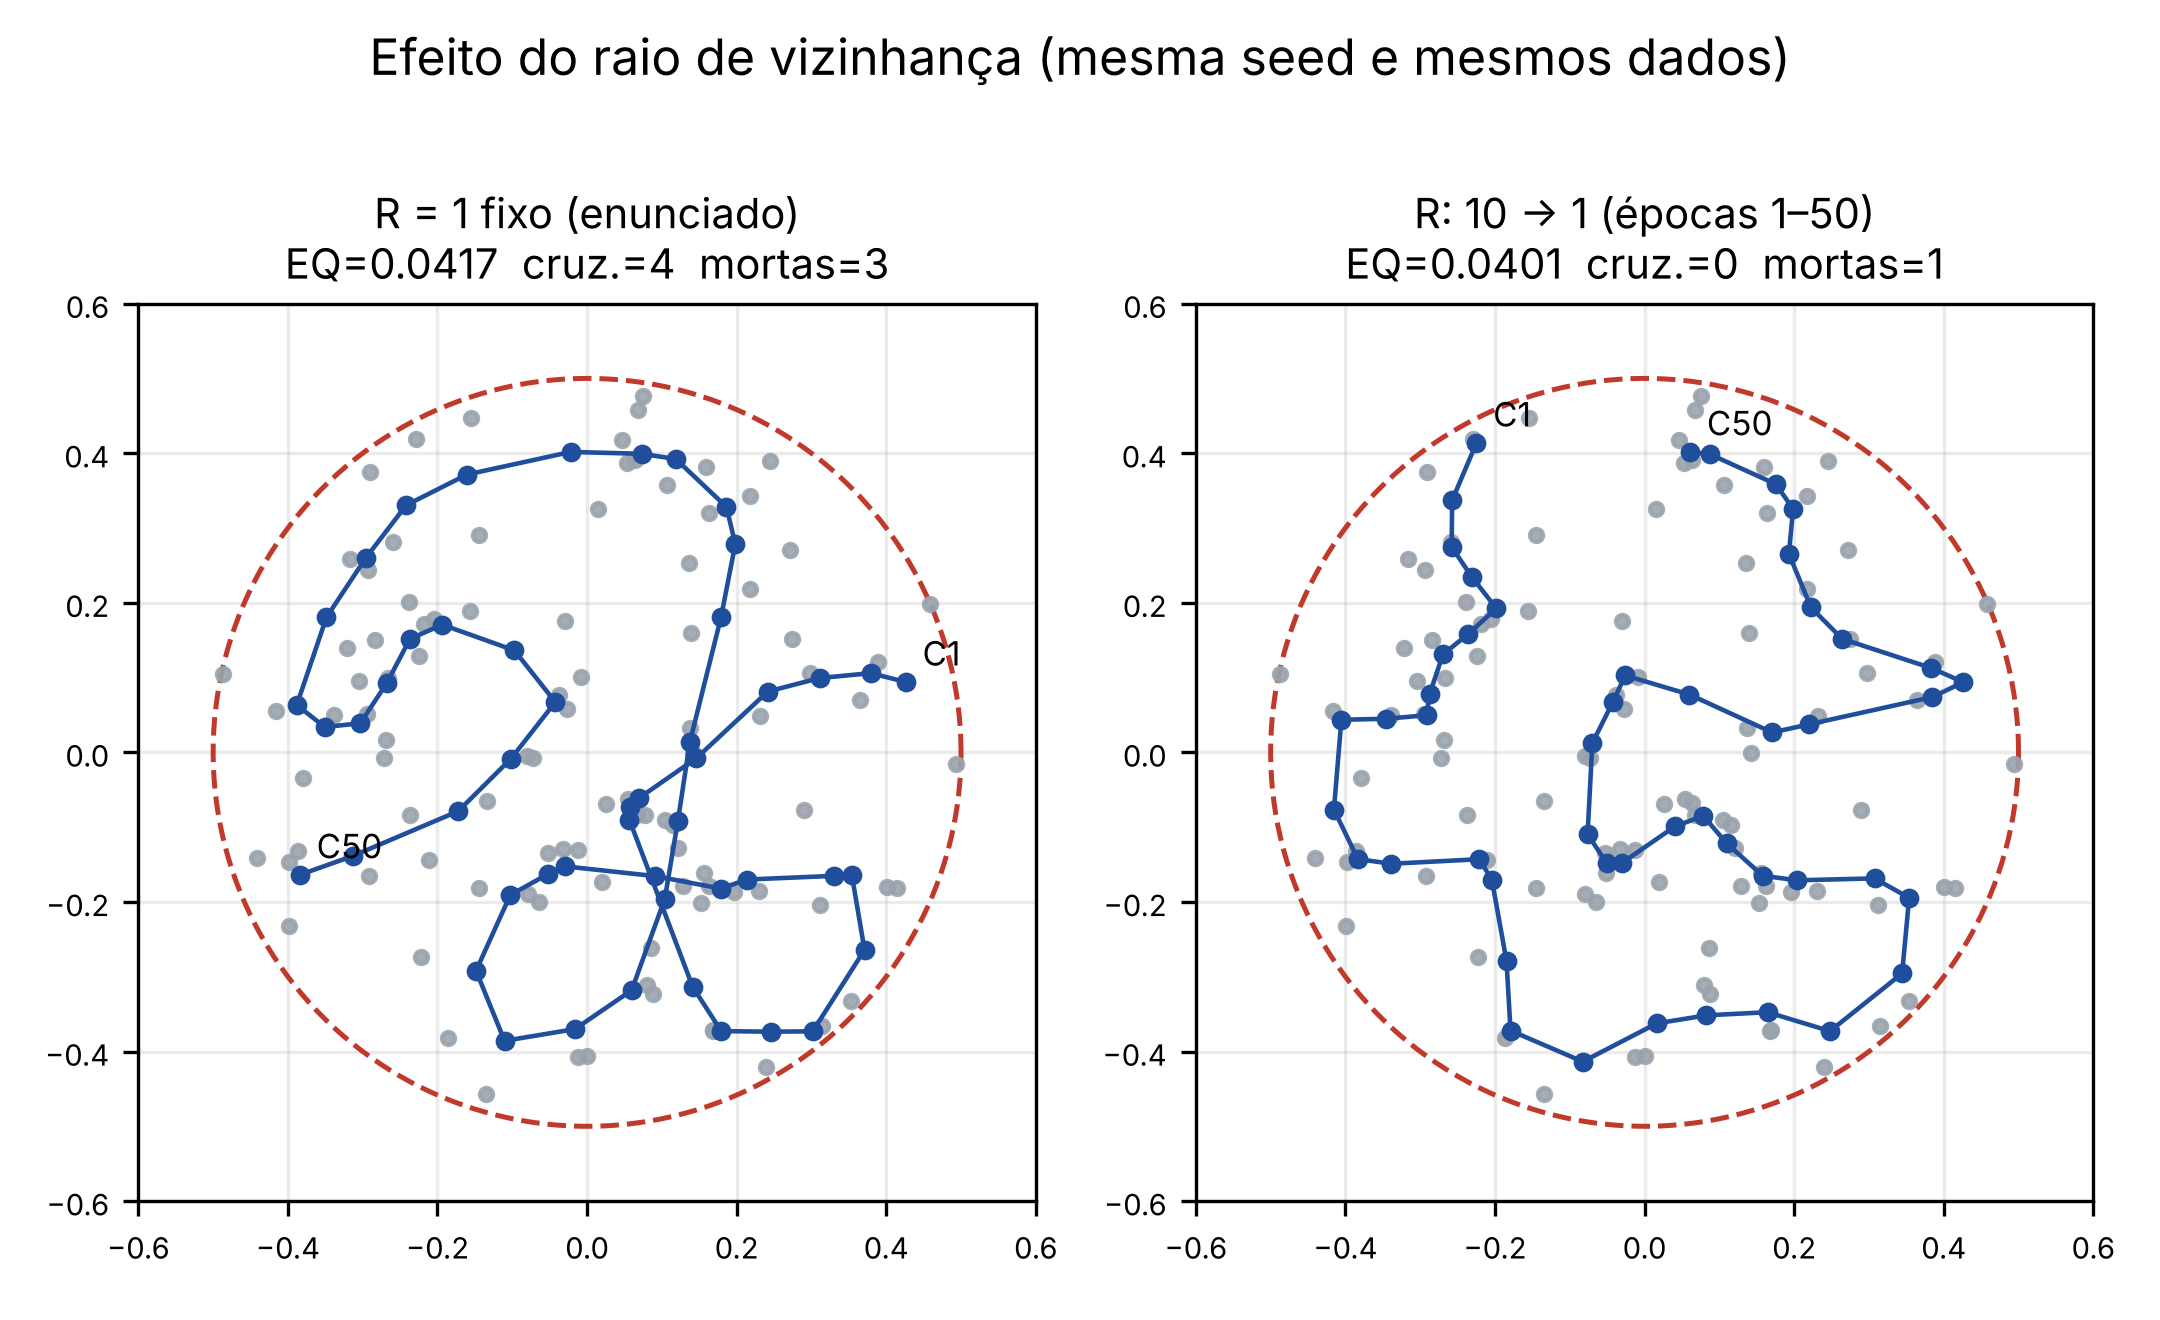

In [14]:
res_raio = treinar(dados, seed=SEED_PADRAO, raio_fn=raio_decrescente)
salvar_comparacao({"R = 1 fixo (enunciado)": principal, "R: 10 → 1 (épocas 1–50)": res_raio},
                  dados, os.path.join(PASTA_FIG, "comparacao_raio.png"),
                  "Efeito do raio de vizinhança (mesma seed e mesmos dados)")
display(Image(os.path.join(PASTA_FIG, "comparacao_raio.png"), width=700))

## 12. Conclusões

- A rede reproduz o comportamento esperado do Exercício 4.1: o emaranhado inicial se recolhe para dentro do disco nas primeiras ~10 épocas e a cadeia passa a serpentear pela região dos dados, com erro de quantização caindo de ≈0,14 para ≈0,04.
- Com **R = 1 fixo**, a ordenação global é limitada: pequenos nós formados no início tendem a persistir (2–4 cruzamentos na maioria das seeds; a seed 1 terminou sem nenhum).
- O tipo de decaimento de $\alpha$ muda pouco a configuração final; o exponencial "congela" o mapa mais cedo.
- Com raio inicial grande (extra), a mesma rede termina sem cruzamentos — evidência de que a vizinhança ampla na fase inicial é o que garante a ordenação topológica global.